In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Clean Data (Simulating SQLAlchemy PostgreSQL pull)
pl = pd.read_csv('../data/clean/clean_profit_loss.csv')
bs = pd.read_csv('../data/clean/clean_balance_sheet.csv')
cf = pd.read_csv('../data/clean/clean_cash_flow.csv')
sectors = pd.read_csv('../data/raw/sector_mapping.csv')

# Exclude TTM for historical metric stability
pl = pl[pl['year_label'] != 'TTM']
bs = bs[bs['year_label'] != 'TTM']
cf = cf[cf['year_label'] != 'TTM']

# 2. Compute Base Metrics per Company
df_scores = pd.DataFrame({'symbol': pl['symbol'].unique()})

# A. Profitability (Avg OPM % & NPM %)
prof = pl.groupby('symbol')[['opm_pct', 'net_profit_margin_pct']].mean().reset_index()
prof['profitability_raw'] = (prof['opm_pct'].rank(pct=True) + prof['net_profit_margin_pct'].rank(pct=True)) / 2
df_scores = df_scores.merge(prof[['symbol', 'profitability_raw']], on='symbol', how='left')

# B. Revenue Growth (3Y CAGR approximation using latest vs 3 years ago)
def calc_3y_growth(group):
    g = group.sort_values('year_id')
    if len(g) >= 4 and g.iloc[-4]['sales'] > 0:
        return ((g.iloc[-1]['sales'] / g.iloc[-4]['sales']) ** (1/3) - 1) * 100
    return np.nan

growth = pl.groupby('symbol').apply(calc_3y_growth).reset_index(name='sales_cagr_3y')
growth['growth_raw'] = growth['sales_cagr_3y'].rank(pct=True)
growth.loc[growth['sales_cagr_3y'] < 5, 'growth_raw'] *= 0.5 # Penalize low growth
df_scores = df_scores.merge(growth[['symbol', 'growth_raw']], on='symbol', how='left')

# C. Leverage (Latest Debt to Equity)
latest_bs = bs.sort_values('year_id').groupby('symbol').tail(1)
latest_bs['leverage_raw'] = 1 - np.clip((latest_bs['debt_to_equity'] - 0.1) / 1.9, 0, 1) # D/E < 0.1 is 1.0, > 2.0 is 0.0
latest_bs.loc[latest_bs['debt_to_equity'] < 0.1, 'leverage_raw'] = 1.0
df_scores = df_scores.merge(latest_bs[['symbol', 'leverage_raw']], on='symbol', how='left')

# D. Cash Flow Quality (Avg Cash Conversion)
ccr = cf.groupby('symbol')['cash_conversion_ratio'].mean().reset_index()
ccr['cashflow_raw'] = np.clip(ccr['cash_conversion_ratio'] / 1.2, 0, 1) # > 1.2 gets max score
df_scores = df_scores.merge(ccr[['symbol', 'cashflow_raw']], on='symbol', how='left')

# E. Dividend Track Record (Consistency over 5 years)
def calc_div(group):
    g = group.sort_values('year_id').tail(5)['dividend_payout_pct'].dropna()
    if len(g) == 0: return 0
    consistency = (g > 0).sum() / len(group.tail(5))
    strength = min(g.mean() / 30, 1.0)
    return consistency * strength

div = pl.groupby('symbol').apply(calc_div).reset_index(name='dividend_raw')
df_scores = df_scores.merge(div[['symbol', 'dividend_raw']], on='symbol', how='left')

# F. Growth Trend (Slope of last 5 years sales)
def calc_trend(group):
    g = group.sort_values('year_id').tail(5)['sales'].dropna()
    if len(g) < 3 or g.mean() == 0: return 0
    slope, _ = np.polyfit(np.arange(len(g)), g.values, 1)
    return slope / g.mean()

trend = pl.groupby('symbol').apply(calc_trend).reset_index(name='trend_slope')
trend['trend_raw'] = trend['trend_slope'].rank(pct=True)
df_scores = df_scores.merge(trend[['symbol', 'trend_raw']], on='symbol', how='left')

# Clear Banks/NBFCs from Leverage and Cashflow penalties
fin_symbols = sectors[sectors['sector'].isin(['Banking', 'NBFC', 'Insurance'])]['symbol']
df_scores.loc[df_scores['symbol'].isin(fin_symbols), ['leverage_raw', 'cashflow_raw']] = np.nan

print("✅ Base Model Features Engineered.")

✅ Base Model Features Engineered.


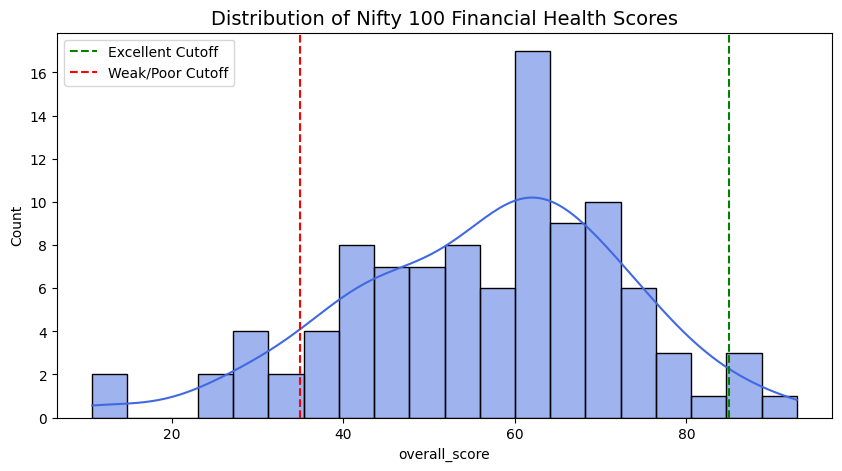

In [2]:
# Base PRD Weights
WEIGHTS = {
    'profitability': 25,
    'growth': 20,
    'leverage': 20,
    'cashflow': 15,
    'dividend': 10,
    'trend': 10
}

def calculate_final_score(df, w_dict):
    df_temp = df.copy()
    df_temp['earned'] = 0.0
    df_temp['available'] = 0.0
    
    metrics = ['profitability_raw', 'growth_raw', 'leverage_raw', 'cashflow_raw', 'dividend_raw', 'trend_raw']
    w_keys = ['profitability', 'growth', 'leverage', 'cashflow', 'dividend', 'trend']
    
    for metric, w_key in zip(metrics, w_keys):
        valid = df_temp[metric].notna()
        df_temp.loc[valid, 'earned'] += df_temp.loc[valid, metric] * w_dict[w_key]
        df_temp.loc[valid, 'available'] += w_dict[w_key]
        
    # Scale to 100 based on available weights (handles missing Banking metrics smoothly)
    return np.where(df_temp['available'] > 0, (df_temp['earned'] / df_temp['available']) * 100, np.nan)

df_scores['overall_score'] = calculate_final_score(df_scores, WEIGHTS)

# Assign Health Labels
def get_label(score):
    if pd.isna(score): return 'UNKNOWN'
    if score >= 85: return 'EXCELLENT'
    if score >= 70: return 'GOOD'
    if score >= 50: return 'AVERAGE'
    if score >= 35: return 'WEAK'
    return 'POOR'

df_scores['health_label'] = df_scores['overall_score'].apply(get_label)

# 3. Visualize Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_scores['overall_score'].dropna(), bins=20, kde=True, color='royalblue')
plt.axvline(85, color='green', linestyle='--', label='Excellent Cutoff')
plt.axvline(35, color='red', linestyle='--', label='Weak/Poor Cutoff')
plt.title('Distribution of Nifty 100 Financial Health Scores', fontsize=14)
plt.legend()
plt.show()

In [3]:
# 4. Cross-Validate Benchmark Companies
benchmarks = ['TCS', 'HDFCBANK', 'WIPRO', 'ADANIPOWER', 'APOLLOHOSP']
print("🔍 Cross-Validation of Benchmark Companies:")
display(df_scores[df_scores['symbol'].isin(benchmarks)][['symbol', 'overall_score', 'health_label']].sort_values('overall_score', ascending=False))

# 5. Sensitivity Analysis
# What if we heavily favor Growth (40%) and ignore Leverage (0%)?
SENSITIVE_WEIGHTS = {
    'profitability': 20,
    'growth': 40,      # Doubled
    'leverage': 0,     # Ignored
    'cashflow': 20,
    'dividend': 10,
    'trend': 10
}

df_scores['score_growth_biased'] = calculate_final_score(df_scores, SENSITIVE_WEIGHTS)
df_scores['score_shift'] = df_scores['score_growth_biased'] - df_scores['overall_score']

print("\n📈 Sensitivity Analysis: Biggest Winners if Growth is Overweighted (Leverage Ignored)")
display(df_scores.nlargest(5, 'score_shift')[['symbol', 'overall_score', 'score_growth_biased', 'score_shift']])

print("\n📉 Sensitivity Analysis: Biggest Losers if Growth is Overweighted")
display(df_scores.nsmallest(5, 'score_shift')[['symbol', 'overall_score', 'score_growth_biased', 'score_shift']])

# Export finalized scores for Power BI (simulating PostgreSQL load)
df_scores[['symbol', 'overall_score', 'health_label']].to_csv('../data/clean/fact_ml_scores_export.csv', index=False)
print("\n✅ Final scores exported to CSV.")

🔍 Cross-Validation of Benchmark Companies:


,symbol,overall_score,health_label
38,HDFCBANK,84.787102,GOOD
85,TCS,74.602020,GOOD
5,ADANIPOWER,60.116470,AVERAGE
7,APOLLOHOSP,46.839430,WEAK
96,WIPRO,42.230769,WEAK



📈 Sensitivity Analysis: Biggest Winners if Growth is Overweighted (Leverage Ignored)


,symbol,overall_score,score_growth_biased,score_shift
87,TITAN,58.530051,80.179798,21.649747
3,ADANIGREEN,40.810546,58.320122,17.509576
2,ADANIENT,35.232068,51.814141,16.582073
97,ZOMATO,47.317405,63.256313,15.938908
83,TATAPOWER,57.273441,72.066667,14.793226



📉 Sensitivity Analysis: Biggest Losers if Growth is Overweighted


,symbol,overall_score,score_growth_biased,score_shift
27,DIVISLAB,59.995688,38.747787,-21.247902
40,HEROMOTOCO,52.881237,31.886430,-20.994807
81,TATACONSUM,41.830348,23.605058,-18.225291
28,DLF,61.173136,43.385253,-17.787883
42,HINDUNILVR,71.023737,54.550505,-16.473232



✅ Final scores exported to CSV.
